In [1]:
import pandas as pd
import numpy as np
import torch

from pathlib import Path
from sklearn.preprocessing import LabelEncoder

# Semilla para reproducibilidad
torch.manual_seed(42)
np.random.seed(42)

# Localizar dataset
carpeta = Path("data")

if not carpeta.exists():
    carpeta = Path("../data")

df = pd.read_csv(
    carpeta / "SGSST_auditorias_sinteticas_5000.csv"
)

# Separar datos
train = df[df["split"] == "train"].copy()
val = df[df["split"] == "val"].copy()
test = df[df["split"] == "test"].copy()

# Codificar las categorías
encoder = LabelEncoder()
encoder.fit(train["categoria"])

y_train = encoder.transform(train["categoria"])
y_val = encoder.transform(val["categoria"])

num_clases = len(encoder.classes_)

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Dispositivo:", device)
print("Entrenamiento:", len(train))
print("Validación:", len(val))
print("Prueba reservada:", len(test))
print("Número de categorías:", num_clases)

Dispositivo: cuda
Entrenamiento: 3752
Validación: 624
Prueba reservada: 624
Número de categorías: 12


In [2]:
from transformers import AutoTokenizer, AutoModel

modelo_id = (
    "sentence-transformers/"
    "paraphrase-multilingual-MiniLM-L12-v2"
)

tokenizer = AutoTokenizer.from_pretrained(modelo_id)

transformer = AutoModel.from_pretrained(
    modelo_id
)

transformer = transformer.to(device)

print("Transformer cargado correctamente")
print("Dispositivo:", device)
print("Dimensión oculta:", transformer.config.hidden_size)

parametros = sum(
    p.numel() for p in transformer.parameters()
)

print(f"Parámetros del Transformer: {parametros:,}")

d:\VIVIAN\Uis\Quinto semestre\Deep Learning\Proyecto Mini-Transforms\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2551.33it/s]


Transformer cargado correctamente
Dispositivo: cuda
Dimensión oculta: 384
Parámetros del Transformer: 117,653,760


In [3]:
MAX_LENGTH = 96

tokens_train = tokenizer(
    train["hallazgo"].tolist(),
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH,
    return_tensors="pt"
)

tokens_val = tokenizer(
    val["hallazgo"].tolist(),
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH,
    return_tensors="pt"
)

print("Tokenización completada")

print("Entrenamiento:")
print(tokens_train["input_ids"].shape)

print("\nValidación:")
print(tokens_val["input_ids"].shape)

print("\nLongitud máxima:", MAX_LENGTH)

Tokenización completada
Entrenamiento:
torch.Size([3752, 96])

Validación:
torch.Size([624, 96])

Longitud máxima: 96


In [4]:
longitudes = [
    len(tokenizer.encode(texto))
    for texto in df["hallazgo"]
]

longitudes = np.array(longitudes)

print("Longitud promedio:", round(longitudes.mean(), 2))
print("Longitud máxima:", longitudes.max())
print("Percentil 95:", np.percentile(longitudes, 95))

exceden = (longitudes > MAX_LENGTH).sum()

print("Textos que superan 96 tokens:", exceden)
print("Porcentaje:", round(exceden / len(df) * 100, 2), "%")

Longitud promedio: 28.2
Longitud máxima: 40
Percentil 95: 34.0
Textos que superan 96 tokens: 0
Porcentaje: 0.0 %


In [5]:
from torch.utils.data import Dataset, DataLoader

MAX_LENGTH = 48
BATCH_SIZE = 4

class DatasetSST(Dataset):

    def __init__(self, textos, etiquetas, tokenizer):

        self.tokens = tokenizer(
            textos,
            truncation=True,
            padding="max_length",
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )

        self.etiquetas = torch.tensor(
            etiquetas,
            dtype=torch.long
        )

    def __len__(self):
        return len(self.etiquetas)

    def __getitem__(self, indice):

        registro = {
            clave: valor[indice]
            for clave, valor in self.tokens.items()
        }

        registro["labels"] = self.etiquetas[indice]

        return registro


dataset_train = DatasetSST(
    train["hallazgo"].tolist(),
    y_train,
    tokenizer
)

dataset_val = DatasetSST(
    val["hallazgo"].tolist(),
    y_val,
    tokenizer
)

loader_train = DataLoader(
    dataset_train,
    batch_size=BATCH_SIZE,
    shuffle=True
)

loader_val = DataLoader(
    dataset_val,
    batch_size=8,
    shuffle=False
)

print("Lotes de entrenamiento:", len(loader_train))
print("Lotes de validación:", len(loader_val))

Lotes de entrenamiento: 938
Lotes de validación: 78


In [6]:
import torch.nn as nn
import torch.nn.functional as F

class MiniLMClasificador(nn.Module):

    def __init__(self, transformer, num_clases):
        super().__init__()

        self.transformer = transformer

        self.dropout = nn.Dropout(0.2)

        self.clasificador = nn.Linear(
            transformer.config.hidden_size,
            num_clases
        )

    def forward(self, input_ids, attention_mask):

        # Representaciones del Transformer
        outputs = self.transformer(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # Mean pooling con máscara
        tokens = outputs.last_hidden_state

        mascara = attention_mask.unsqueeze(-1)

        suma = (tokens * mascara).sum(dim=1)

        cantidad = mascara.sum(dim=1).clamp(min=1)

        embeddings = suma / cantidad

        # Capa final de clasificación
        embeddings = self.dropout(embeddings)

        logits = self.clasificador(embeddings)

        return logits


modelo_sst = MiniLMClasificador(
    transformer,
    num_clases
).to(device)

print("Modelo de clasificación creado correctamente")

parametros_entrenables = sum(
    p.numel()
    for p in modelo_sst.parameters()
    if p.requires_grad
)

print("Parámetros entrenables:", parametros_entrenables)

Modelo de clasificación creado correctamente
Parámetros entrenables: 117658380


In [7]:
from torch.optim import AdamW

criterio = nn.CrossEntropyLoss()

optimizador = AdamW(
    [
        {
            "params": modelo_sst.transformer.parameters(),
            "lr": 2e-5
        },
        {
            "params": modelo_sst.clasificador.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=0.01
)

# Precisión mixta para CUDA
usar_amp = device == "cuda"

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=usar_amp
)

print("Optimizador configurado correctamente")
print("Precisión mixta:", usar_amp)

Optimizador configurado correctamente
Precisión mixta: True


In [8]:
# Tomar un lote de entrenamiento
batch = next(iter(loader_train))

input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)
labels = batch["labels"].to(device)

modelo_sst.train()

with torch.autocast(
    device_type="cuda" if usar_amp else "cpu",
    enabled=usar_amp
):

    salidas = modelo_sst(
        input_ids,
        attention_mask
    )

    perdida = criterio(salidas, labels)

print("Dimensiones de salida:", salidas.shape)
print("Pérdida inicial:", round(perdida.item(), 4))
print(
    "Memoria GPU utilizada (MB):",
    round(torch.cuda.memory_allocated() / 1024**2, 2)
    if usar_amp else "CPU"
)

Dimensiones de salida: torch.Size([4, 12])
Pérdida inicial: 2.3965
Memoria GPU utilizada (MB): 537.53


In [9]:
import copy
import gc
from sklearn.metrics import accuracy_score, f1_score

# Liberar variables de la prueba anterior, si existen
for nombre in ["salidas", "perdida", "batch",
               "input_ids", "attention_mask", "labels"]:
    if nombre in globals():
        del globals()[nombre]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Configuración
EPOCAS = 4
ACUMULACION = 4
PACIENCIA = 2

mejor_f1 = -1.0
mejor_epoca = 0
mejores_pesos = None
epocas_sin_mejora = 0

historial = {
    "train_loss": [],
    "val_accuracy": [],
    "val_f1": []
}

for epoca in range(EPOCAS):

    # ENTRENAMIENTO
    modelo_sst.train()
    optimizador.zero_grad(set_to_none=True)

    perdida_acumulada = 0.0
    total_ejemplos = 0

    for paso, batch in enumerate(loader_train):

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        # Ajustar el divisor para el último grupo incompleto
        inicio_grupo = (
            paso // ACUMULACION
        ) * ACUMULACION

        tam_grupo = min(
            ACUMULACION,
            len(loader_train) - inicio_grupo
        )

        with torch.autocast(
            device_type="cuda" if usar_amp else "cpu",
            enabled=usar_amp
        ):
            logits = modelo_sst(
                input_ids,
                attention_mask
            )

            loss = criterio(logits, labels)

            loss_backward = loss / tam_grupo

        scaler.scale(loss_backward).backward()

        perdida_acumulada += (
            loss.item() * len(labels)
        )
        total_ejemplos += len(labels)

        # Actualizar los pesos después de acumular gradientes
        if (
            (paso + 1) % ACUMULACION == 0
            or paso + 1 == len(loader_train)
        ):

            scaler.unscale_(optimizador)

            torch.nn.utils.clip_grad_norm_(
                modelo_sst.parameters(),
                max_norm=1.0
            )

            scaler.step(optimizador)
            scaler.update()

            optimizador.zero_grad(set_to_none=True)

        if (paso + 1) % 200 == 0:
            print(
                f"Época {epoca+1} | "
                f"Lote {paso+1}/{len(loader_train)}"
            )

    train_loss = perdida_acumulada / total_ejemplos

    # VALIDACIÓN
    modelo_sst.eval()

    predicciones = []
    etiquetas_reales = []

    with torch.no_grad():

        for batch in loader_val:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            with torch.autocast(
                device_type="cuda" if usar_amp else "cpu",
                enabled=usar_amp
            ):
                logits = modelo_sst(
                    input_ids,
                    attention_mask
                )

            pred = torch.argmax(
                logits, dim=1
            )

            predicciones.extend(
                pred.cpu().tolist()
            )

            etiquetas_reales.extend(
                labels.cpu().tolist()
            )

    accuracy = accuracy_score(
        etiquetas_reales,
        predicciones
    )

    macro_f1 = f1_score(
        etiquetas_reales,
        predicciones,
        average="macro",
        zero_division=0
    )

    historial["train_loss"].append(train_loss)
    historial["val_accuracy"].append(accuracy)
    historial["val_f1"].append(macro_f1)

    print(f"\nÉPOCA {epoca+1}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Val Accuracy: {accuracy:.4f}")
    print(f"Val Macro-F1: {macro_f1:.4f}")
    print("-" * 40)

    # Guardar el mejor modelo según Macro-F1
    if macro_f1 > mejor_f1 + 1e-4:

        mejor_f1 = macro_f1
        mejor_epoca = epoca + 1

        mejores_pesos = {
            k: v.detach().cpu().clone()
            for k, v in modelo_sst.state_dict().items()
        }

        epocas_sin_mejora = 0

        print("Nuevo mejor modelo registrado.")

    else:
        epocas_sin_mejora += 1

    if epocas_sin_mejora >= PACIENCIA:
        print("\nEarly stopping activado.")
        break

# Recuperar el mejor modelo
modelo_sst.load_state_dict(mejores_pesos)
print("\nENTRENAMIENTO FINALIZADO")
print("Mejor época:", mejor_epoca)
print("Mejor Macro-F1:", round(mejor_f1, 4))

Época 1 | Lote 200/938
Época 1 | Lote 400/938
Época 1 | Lote 600/938
Época 1 | Lote 800/938

ÉPOCA 1
Train Loss: 0.8448
Val Accuracy: 0.5785
Val Macro-F1: 0.5253
----------------------------------------
Nuevo mejor modelo registrado.
Época 2 | Lote 200/938
Época 2 | Lote 400/938
Época 2 | Lote 600/938
Época 2 | Lote 800/938

ÉPOCA 2
Train Loss: 0.0193
Val Accuracy: 0.5721
Val Macro-F1: 0.5218
----------------------------------------
Época 3 | Lote 200/938
Época 3 | Lote 400/938
Época 3 | Lote 600/938
Época 3 | Lote 800/938

ÉPOCA 3
Train Loss: 0.0085
Val Accuracy: 0.5721
Val Macro-F1: 0.5218
----------------------------------------

Early stopping activado.

ENTRENAMIENTO FINALIZADO
Mejor época: 1
Mejor Macro-F1: 0.5253


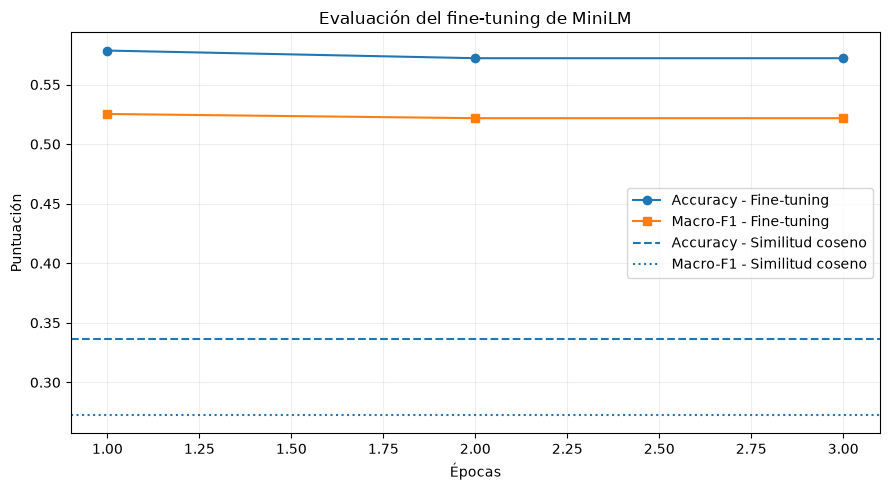

In [10]:
import matplotlib.pyplot as plt

epocas = range(1, len(historial["val_f1"]) + 1)

plt.figure(figsize=(9, 5))

plt.plot(
    epocas,
    historial["val_accuracy"],
    marker="o",
    label="Accuracy - Fine-tuning"
)

plt.plot(
    epocas,
    historial["val_f1"],
    marker="s",
    label="Macro-F1 - Fine-tuning"
)

plt.axhline(
    0.3365,
    linestyle="--",
    label="Accuracy - Similitud coseno"
)

plt.axhline(
    0.2724,
    linestyle=":",
    label="Macro-F1 - Similitud coseno"
)

plt.xlabel("Épocas")
plt.ylabel("Puntuación")
plt.title("Evaluación del fine-tuning de MiniLM")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [11]:
from pathlib import Path
import json
import torch

# Carpeta de salida
ruta_modelo = Path("models/minilm_sst_finetuned")
ruta_modelo.mkdir(parents=True, exist_ok=True)

# Guardar los pesos del modelo completo
torch.save(
    modelo_sst.state_dict(),
    ruta_modelo / "modelo_sst.pth"
)

# Guardar tokenizador
tokenizer.save_pretrained(ruta_modelo)

# Guardar correspondencia de categorías
with open(
    ruta_modelo / "categorias.json",
    "w",
    encoding="utf-8"
) as archivo:

    json.dump(
        encoder.classes_.tolist(),
        archivo,
        ensure_ascii=False,
        indent=4
    )

print("Modelo guardado correctamente en:", ruta_modelo)

Modelo guardado correctamente en: models\minilm_sst_finetuned


REPORTE DEL MINILM AJUSTADO

                                                    precision    recall  f1-score   support

                             Condiciones locativas       0.00      0.00      0.00        52
                         Control documental SG-SST       1.00      1.00      1.00        52
                  Elementos de proteccion personal       1.00      1.00      1.00        52
                      Formacion y competencias SST       0.00      0.00      0.00        52
                       Gestion SST de contratistas       1.00      0.94      0.97        52
                    Gestion de sustancias quimicas       0.50      1.00      0.67        52
Identificacion de peligros y valoracion de riesgos       0.00      0.00      0.00        52
                      Inspecciones y mantenimiento       0.00      0.00      0.00        52
          Investigacion de incidentes y accidentes       1.00      1.00      1.00        52
             Preparacion y respuesta a emergencias

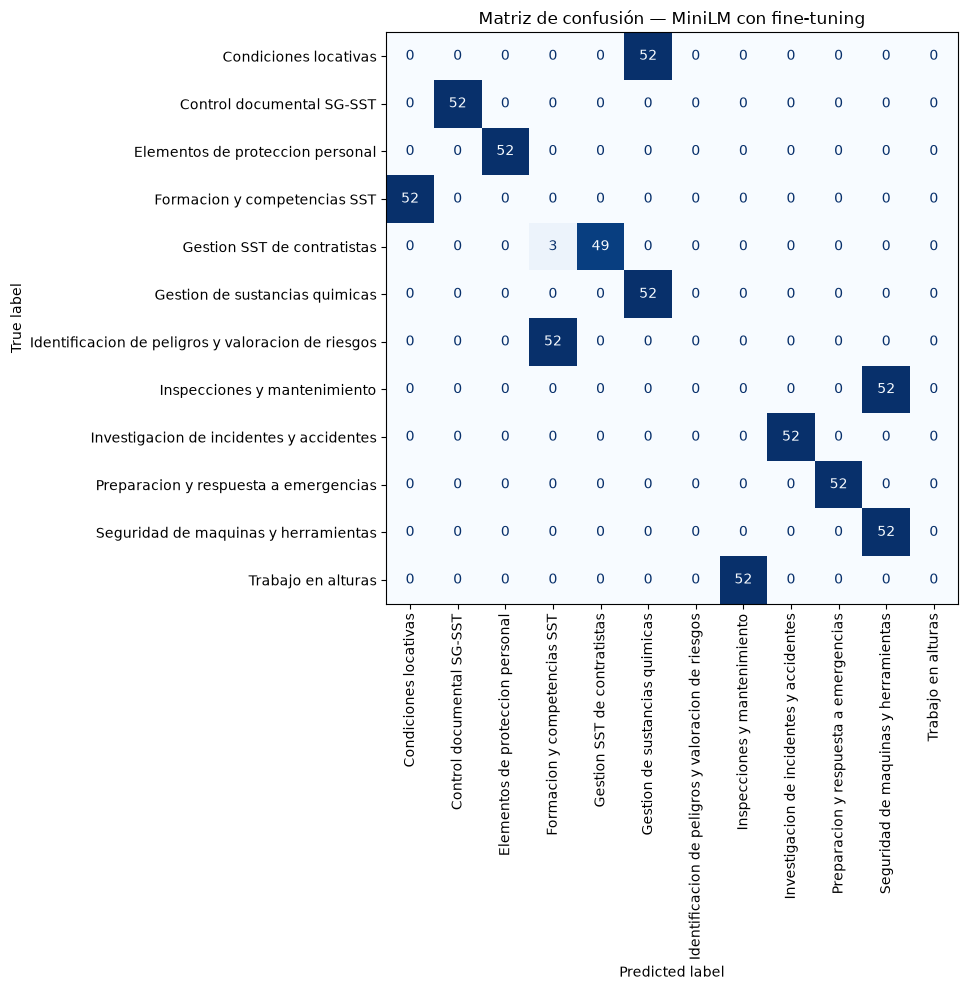

In [12]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

modelo_sst.eval()

predicciones = []
reales = []

with torch.no_grad():

    for batch in loader_val:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        logits = modelo_sst(
            input_ids,
            attention_mask
        )

        pred = torch.argmax(logits, dim=1)

        predicciones.extend(pred.cpu().tolist())
        reales.extend(batch["labels"].tolist())

print("REPORTE DEL MINILM AJUSTADO\n")

print(
    classification_report(
        reales,
        predicciones,
        target_names=encoder.classes_,
        zero_division=0
    )
)

matriz = confusion_matrix(reales, predicciones)

fig, ax = plt.subplots(figsize=(13, 10))

ConfusionMatrixDisplay(
    matriz,
    display_labels=encoder.classes_
).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False
)

plt.title("Matriz de confusión — MiniLM con fine-tuning")
plt.tight_layout()
plt.show()

In [13]:
# Preparar el conjunto de prueba
y_test = encoder.transform(test["categoria"])

dataset_test = DatasetSST(
    test["hallazgo"].tolist(),
    y_test,
    tokenizer
)

loader_test = DataLoader(
    dataset_test,
    batch_size=8,
    shuffle=False
)

print("Registros de prueba:", len(dataset_test))
print("Lotes de prueba:", len(loader_test))
print("Categorías:", num_clases)

Registros de prueba: 624
Lotes de prueba: 78
Categorías: 12


In [14]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

# Poner el modelo en modo evaluación
modelo_sst.eval()

predicciones_test = []
reales_test = []

with torch.inference_mode():

    for batch in loader_test:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        # Predicciones del MiniLM ajustado
        logits = modelo_sst(
            input_ids,
            attention_mask
        )

        pred = torch.argmax(logits, dim=1)

        predicciones_test.extend(pred.cpu().tolist())
        reales_test.extend(batch["labels"].tolist())

# Calcular métricas
accuracy_test = accuracy_score(
    reales_test,
    predicciones_test
)

f1_test = f1_score(
    reales_test,
    predicciones_test,
    average="macro",
    zero_division=0
)

print("RESULTADOS FINALES - MINILM FINE-TUNING")
print("-" * 45)

print(f"Accuracy TEST: {accuracy_test:.4f}")
print(f"Macro-F1 TEST: {f1_test:.4f}")

print("\nREPORTE POR CATEGORÍA\n")

print(
    classification_report(
        reales_test,
        predicciones_test,
        target_names=encoder.classes_,
        zero_division=0
    )
)

RESULTADOS FINALES - MINILM FINE-TUNING
---------------------------------------------
Accuracy TEST: 0.5064
Macro-F1 TEST: 0.4688

REPORTE POR CATEGORÍA

                                                    precision    recall  f1-score   support

                             Condiciones locativas       1.00      1.00      1.00        52
                         Control documental SG-SST       0.34      1.00      0.50        52
                  Elementos de proteccion personal       0.00      0.00      0.00        52
                      Formacion y competencias SST       0.06      0.04      0.05        52
                       Gestion SST de contratistas       1.00      1.00      1.00        52
                    Gestion de sustancias quimicas       1.00      1.00      1.00        52
Identificacion de peligros y valoracion de riesgos       0.00      0.00      0.00        52
                      Inspecciones y mantenimiento       1.00      0.04      0.07        52
          Investi

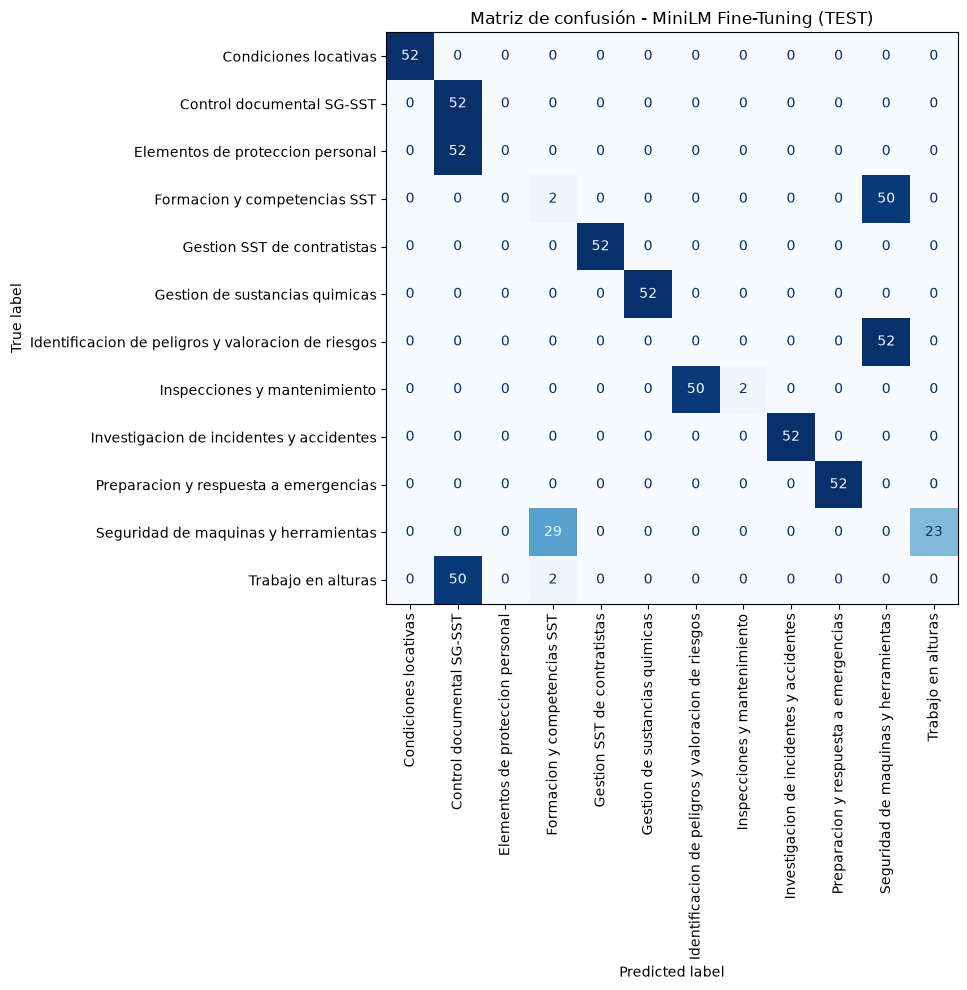

In [15]:
# Crear matriz de confusión
matriz_test = confusion_matrix(
    reales_test,
    predicciones_test
)

fig, ax = plt.subplots(figsize=(13, 10))

ConfusionMatrixDisplay(
    confusion_matrix=matriz_test,
    display_labels=encoder.classes_
).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False
)

plt.title("Matriz de confusión - MiniLM Fine-Tuning (TEST)")
plt.tight_layout()
plt.show()